# 5.58: Bedridden Boys Problem

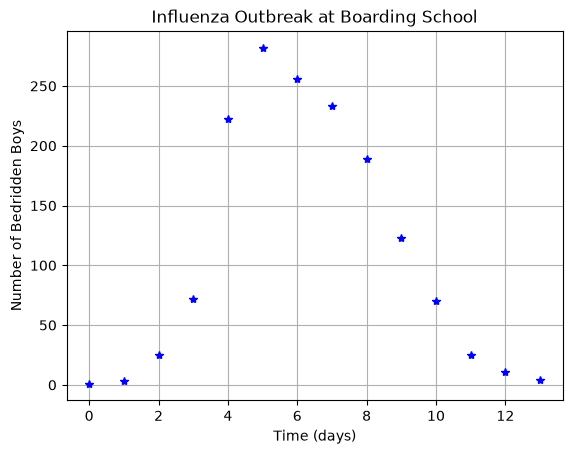

In [1]:
import numpy as np
import pandas as pd

data = np.array(pd.read_csv('../../data/Exercise5_boys.csv'))
# Exercise5_boys.csv (local copy of the course dataset)

import matplotlib.pyplot as plt
# Assuming the CSV has two columns: the first for time and the second for the number of bedridden boys
plt.plot(data[:, 0], data[:, 1], 'b*')  # Plot as blue stars
plt.xlabel('Time (days)')
plt.ylabel('Number of Bedridden Boys')
plt.title('Influenza Outbreak at Boarding School')
plt.grid()
plt.show()

In [2]:
Tambient = 0  # Assuming no bedridden boys at equilibrium
dt = 1  # One day time steps to match the daily data
t0 = 0  # The data starts at day 0
tmax = 14  # One day beyond the last day of data (if day 13 is the last day)
t = np.arange(t0, tmax + dt, dt)  # Set up the time points
f = lambda t, x, k: -k * (x - Tambient)  # The differential equation
x0 = data[0, 1]  # The initial number of bedridden boys, assuming data[0, 1] is the first entry for bedridden boys

In [3]:
# Numerical solution using the Euler method
def numericalSolution(k):
    k = float(np.ravel(k)[0])  # scipy.optimize passes a one-element array
    x = np.zeros_like(t, dtype=float)
    x[0] = x0  # Set the initial condition
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + dt * f(t[n], x[n], k)
    return t, x

In [4]:
indices = []
for j in range(len(t)):
    # Find the index where the time is closest to the time
    index = np.argmin(np.abs(data[:, 0] - t[j]))
    # if the closest time is the time at t[j]
    if data[index, 0] == t[j]:
        indices.append(index)

In [5]:
def dataMatcher(k):
    t, x = numericalSolution(k)
    err = []
    counter = 0
    for n in indices:
        err.append( (data[counter,1] - x[int(n)])**2 )
        counter += 1
    print("For k=",k[0],",  SSRes=",np.sum(err)) # optional
    return np.sum(err)

For k= 0.1 ,  SSRes= 309366.0083048144
For k= 0.1000000149011612 ,  SSRes= 309366.00845897425
For k= -0.91 ,  SSRes= 27756660.721174087
For k= -0.9099999850988388 ,  SSRes= 27756655.256416164
For k= -0.20747167836066963 ,  SSRes= 300657.6662006634
For k= -0.20747166345950843 ,  SSRes= 300657.66703320853
For k= -0.6123696354164826 ,  SSRes= 609195.3219732402
For k= -0.6123696205153214 ,  SSRes= 609195.2381593457
For k= -0.3237862131644671 ,  SSRes= 293235.57756308606
For k= -0.3237861982633059 ,  SSRes= 293235.57847398653
For k= -0.4541145770563735 ,  SSRes= 298844.8601143969
For k= -0.4541145621552123 ,  SSRes= 298844.8558209215
For k= -0.37398967649503234 ,  SSRes= 291021.3597009933
For k= -0.37398966159387115 ,  SSRes= 291021.3599622243
For k= -0.3851822617132079 ,  SSRes= 290929.578684306
For k= -0.3851822468120467 ,  SSRes= 290929.57865557185
For k= -0.30895613286845197 ,  SSRes= 294176.4206767755
For k= -0.3089561179672908 ,  SSRes= 294176.42164992006
For k= -0.38406627424560147 ,

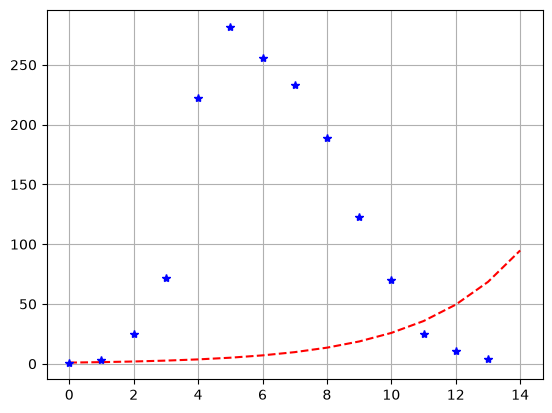

In [6]:
import scipy.optimize as sp
# Choose an initial value of k and put it into the following code 
initial_k_guess = [0.1] 
# in place of the "???".  Note that we are sending a few parameters 
# to the optimization tool.  Be sure to understand these options 
# and take care that these options problem dependent and you will 
# need to choose these again for the next new problem.
K = sp.minimize(dataMatcher, initial_k_guess, options = {'maxiter': 5}, tol=1e-2)
print(K)
t, x = numericalSolution(K.x[0])
plt.plot(t,x,'r--',data[:,0],data[:,1],'b*')
plt.grid()
plt.show()